In [ ]:
from pathlib import Path
import math
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/wallet_features.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the entire project folder in VS Code and place wallet_features.csv in the data folder.')
RESULT_DIR = ROOT/'submission_outputs/results'
FIGURE_DIR = ROOT/'submission_outputs/figures'
for folder in [RESULT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print('Project data located successfully.')
print('Python version:', sys.version.split()[0])


FileNotFoundError: Open the entire project folder in VS Code and place wallet_features.csv in the data folder.

## Data Loading and Validation


In [ ]:
df = pd.read_csv(ROOT/'data/wallet_features.csv')
required = ['wallet', 'total_notional', 'confirmed', 'trade_count', 'unique_markets']
assert set(required).issubset(df.columns), 'Required columns are missing.'
assert df.wallet.notna().all() and df.wallet.is_unique, 'Wallet IDs are missing or duplicated.'
label = df.confirmed.astype(str).str.lower().str.strip()
assert label.isin(['true','false','1','0']).all(), 'The confirmed column contains unrecognized values.'
df['confirmed'] = label.isin(['true','1'])
for col in ['total_notional','trade_count','unique_markets']:
    df[col] = pd.to_numeric(df[col], errors='raise')
    assert df[col].notna().all() and df[col].ge(0).all(), f'{col} contains invalid values.'
print('Total wallets:', len(df), '; Known-positive wallets:', int(df.confirmed.sum()))
display(df.head())
display(df.isna().sum().rename('missing_count').to_frame())


TypeError: unsupported operand type(s) for /: 'NoneType' and 'str'

## Analysis Population



In [ ]:
population = df.copy()
print('Wallets included:', len(population))
print('Known-positive wallets:', int(population.confirmed.sum()))
print('Excluded wallets:', len(df) - len(population))

NameError: name 'df' is not defined

## Transaction-Amount Ranking Baseline



In [ ]:
ranking = population.sort_values(['total_notional','wallet'], ascending=[False,True]).copy()
ranking['rank'] = range(1, len(ranking)+1)
ranking[['wallet','total_notional','confirmed','rank']].to_csv(RESULT_DIR/'baseline_ranking.csv', index=False)
display(ranking[['rank','wallet','total_notional','confirmed']].head(10))


NameError: name 'population' is not defined

## Leave-One-Positive-Out Evaluation of the Baseline


In [ ]:
import numpy as np
import hashlib
import json

SPLIT_SEED = 0
pos = np.flatnonzero(population.confirmed.to_numpy())
unl = np.flatnonzero(~population.confirmed.to_numpy())
spend = population.total_notional.to_numpy()
wallet_ids = population.wallet.to_numpy()
rng = np.random.default_rng(SPLIT_SEED)
fold_rows = []
for i in pos:
    test_unl = rng.choice(unl, size=len(unl) // 5, replace=False)
    spend_pct = float(np.mean(spend[test_unl] >= spend[i]))
    fold_rows.append(dict(
        insider=wallet_ids[i], spend_pct=spend_pct,
        test_unlabeled_count=len(test_unl), test_wallet_count=len(test_unl)+1,
        split_seed=SPLIT_SEED,
        test_unlabeled_indices_sha256=hashlib.sha256(
            test_unl.astype('<i8').tobytes()).hexdigest()))
fold_results = pd.DataFrame(fold_rows)
fold_results.to_csv(RESULT_DIR/'baseline_loio_per_wallet.csv', index=False)

rows = []
for fraction in [0.005, 0.01, 0.025, 0.05, 0.10]:
    hits = int((fold_results.spend_pct <= fraction).sum())
    rows.append(dict(method='Amount baseline (LOIO)', review_fraction=fraction,
                     known_hits=hits, positive_total=len(pos), recall=hits/len(pos)))
summary = pd.DataFrame(rows)
summary.to_csv(RESULT_DIR/'baseline_loio_summary.csv', index=False)
metadata = dict(split_seed=SPLIT_SEED, bot_filter=False,
                source_sha256=hashlib.sha256((ROOT/'data/wallet_features.csv').read_bytes()).hexdigest(),
                population_size=len(population), known_positive_count=len(pos),
                percentile_definition='mean(test_unlabeled_notional >= held_out_positive_notional)',
                note='Matches Grad make_folds and spend_pct; PU models not run here.')
(RESULT_DIR/'baseline_loio_metadata.json').write_text(json.dumps(metadata, indent=2))
print('Evaluation folds:', len(fold_results))
print('Test wallets per fold:', fold_results.test_wallet_count.unique())
display(summary)
display(fold_results[['insider','spend_pct','test_wallet_count']])

NameError: name 'population' is not defined

## Baseline Recovery across Review Thresholds


NameError: name 'summary' is not defined

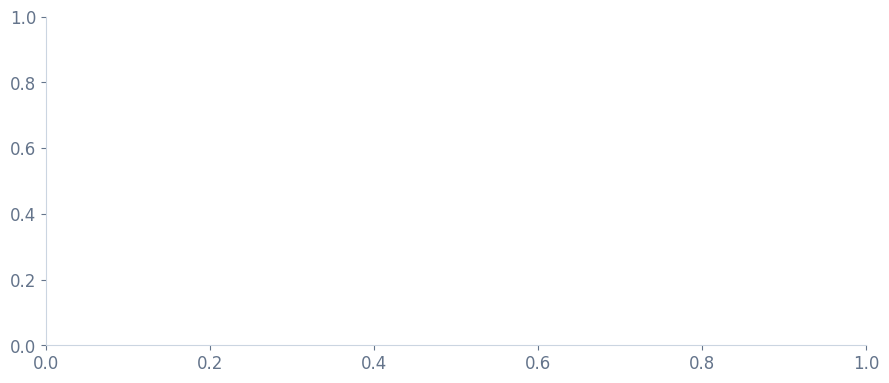

In [ ]:
from matplotlib.ticker import PercentFormatter

# Single-panel baseline figure; all five evaluation thresholds are retained.
# Values summarize one fixed split seed, not repeated-run uncertainty.
with plt.rc_context({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'], 'font.size': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#CBD5E1', 'axes.labelcolor': '#334155',
    'xtick.color': '#64748B', 'ytick.color': '#64748B',
    'pdf.fonttype': 42, 'svg.fonttype': 'none'
}):
    fig, ax = plt.subplots(figsize=(10, 6.2), facecolor='white')
    fig.subplots_adjust(left=0.12, right=0.94, bottom=0.23, top=0.76)
    x = summary.review_fraction.to_numpy() * 100
    y = summary.recall.to_numpy() * 100
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.plot(x, y, color='#2563A6', linewidth=2.6, marker='o', markersize=7,
            markerfacecolor='white', markeredgewidth=2, zorder=3)
    for fraction in [0.01, 0.05, 0.10]:
        row = summary.loc[np.isclose(summary.review_fraction, fraction)].iloc[0]
        ax.annotate(f"{row.recall:.1%} ({int(row.known_hits)}/19)",
                    (fraction*100, row.recall*100), xytext=(0, 30),
                    textcoords='offset points', ha='center', va='bottom',
                    fontsize=12, fontweight='bold', color='#174B7A')
    ax.set(xlim=(0, 11.1), ylim=(0, 105),
           xlabel='Review threshold per test fold',
           ylabel='Held-out known-positive recall')
    ax.set_xticks([0, 1, 2.5, 5, 10])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(axis='both', length=0, pad=9)
    ax.xaxis.labelpad = 14
    ax.yaxis.labelpad = 12
    fig.text(0.12, 0.92, 'How much can amount ranking recover?',
             fontsize=21, fontweight='bold', color='#172B45', va='top')
    fig.text(0.12, 0.845, 'Amount baseline | Leave-one-positive-out evaluation',
             fontsize=12, color='#64748B', va='top')
    fig.text(0.12, 0.095,
             '19 held-out positives across 19 folds; split seed = 0. Ties count against the positive.',
             fontsize=10, color='#64748B')
    fig.text(0.12, 0.06,
             'Each fold ranks one held-out positive against 20% of unlabeled wallets. Matched model comparisons are reported in Sections 8 and 9.',
             fontsize=10, color='#64748B')
    fig.savefig(FIGURE_DIR/'baseline_recall_LOIO.png', dpi=300, facecolor='white')
    fig.savefig(FIGURE_DIR/'baseline_recall_LOIO.pdf', facecolor='white')
    fig.savefig(FIGURE_DIR/'baseline_recall_LOIO.svg', facecolor='white')
    plt.show()


## Model Results and Evaluation Consistency Checks


In [ ]:
import subprocess
import hashlib
import json

RERUN_MODELS = False
result_path = ROOT/'results/pu_loio_per_wallet.csv'
metadata_path = ROOT/'results/model_comparison_metadata.json'
if RERUN_MODELS or not result_path.exists() or not metadata_path.exists():
    subprocess.run([sys.executable, str(ROOT/'scripts/run_pu_comparison.py')], check=True)
model_metadata = json.loads(metadata_path.read_text())
assert model_metadata['source_sha256'] == hashlib.sha256((ROOT/'data/wallet_features.csv').read_bytes()).hexdigest(), 'Data changed. Set RERUN_MODELS = True.'
assert model_metadata['model_source_sha256'] == hashlib.sha256((ROOT/'scripts/pu_bagging_leave_one_insider_out.py').read_bytes()).hexdigest(), 'Model source changed. Set RERUN_MODELS = True.'
model_folds = pd.read_csv(result_path)
matched = fold_results.merge(model_folds, on='insider', suffixes=('_baseline', '_model'), validate='one_to_one')
assert len(matched) == len(fold_results) == 19
assert np.allclose(matched.spend_pct_baseline, matched.spend_pct_model, rtol=0, atol=1e-14), 'Baseline mismatch.'
comparison_rows = []
for method, column in [('Amount ranking', 'spend_pct'), ('Bagging PU - Tree', 'tree_pct'), ('Bagging PU - Logistic', 'logistic_pct')]:
    for fraction in [0.005, 0.01, 0.025, 0.05, 0.10]:
        hits = int((model_folds[column] <= fraction).sum())
        comparison_rows.append(dict(method=method, review_fraction=fraction, known_hits=hits,
                                    positive_total=len(model_folds), recall=hits/len(model_folds)))
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RESULT_DIR/'model_comparison_summary.csv', index=False)
print('Baseline check passed: all 19 fold percentiles match.')
display(comparison.loc[comparison.review_fraction.isin([0.01,0.05,0.10])].reset_index(drop=True))

## Recovery at a 1% Review Threshold

In [ ]:
from matplotlib.ticker import MaxNLocator

METHODS = ['Amount ranking', 'Bagging PU - Tree', 'Bagging PU - Logistic']
COLORS = ['#8796A8', '#D69B51', '#2563A6']
PLOT_STYLE = {'font.family': 'sans-serif', 'font.sans-serif': ['Arial','DejaVu Sans'],
              'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False,
              'axes.edgecolor': '#CBD5E1', 'axes.labelcolor': '#334155',
              'xtick.color': '#64748B', 'ytick.color': '#64748B',
              'pdf.fonttype': 42, 'svg.fonttype': 'none'}

top_one = comparison.loc[np.isclose(comparison.review_fraction, 0.01)].set_index('method').loc[METHODS]
with plt.rc_context(PLOT_STYLE):
    fig, ax = plt.subplots(figsize=(10,6.2), facecolor='white')
    fig.subplots_adjust(left=0.12, right=0.95, bottom=0.23, top=0.75)
    positions = np.arange(len(METHODS))
    ax.bar(positions, top_one.known_hits, width=0.5, color=COLORS)
    for position, (_, row) in zip(positions, top_one.iterrows()):
        ax.text(position, row.known_hits+0.55, f'{int(row.known_hits)}/19 ({row.recall:.1%})',
                ha='center', va='bottom', fontsize=13, fontweight='bold', color='#172B45')
    ax.set_xticks(positions, ['Amount ranking','Bagging PU\nTree','Bagging PU\nLogistic'])
    ax.set(xlim=(-0.6,2.6), ylim=(0,19), ylabel='Held-out positives recovered')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
    ax.tick_params(length=0, pad=10)
    ax.yaxis.labelpad=12
    fig.text(0.12,0.92,'At a 1% review threshold',fontsize=21,fontweight='bold',color='#172B45',va='top')
    fig.text(0.12,0.845,'Amount ranking vs. Bagging PU | Matched test folds',fontsize=12,color='#64748B',va='top')
    fig.text(0.12,0.09,'19 held-out positives; one fixed split/PU seed pair (0, 0). No repeated-run interval shown.',fontsize=10,color='#64748B')
    fig.text(0.12,0.055,'Known-label recovery does not establish insider-trading detection accuracy.',fontsize=10,color='#64748B')
    fig.savefig(FIGURE_DIR/'model_comparison_top1.png',dpi=300,facecolor='white')
    fig.savefig(FIGURE_DIR/'model_comparison_top1.pdf',facecolor='white')
    fig.savefig(FIGURE_DIR/'model_comparison_top1.svg',facecolor='white')
    plt.show()


## Recovery across Review Thresholds



In [ ]:
from matplotlib.ticker import PercentFormatter

with plt.rc_context(PLOT_STYLE):
    fig, ax = plt.subplots(figsize=(10,6.2), facecolor='white')
    fig.subplots_adjust(left=0.12, right=0.94, bottom=0.24, top=0.74)
    for method, color, marker in zip(METHODS,COLORS,['o','s','D']):
        part = comparison.loc[comparison.method.eq(method)].sort_values('review_fraction')
        ax.plot(part.review_fraction*100, part.recall*100, color=color, marker=marker,
                linewidth=2.6, markersize=6, markerfacecolor='white', markeredgewidth=1.8,
                label=method)
    ax.set(xlim=(0,10.7),ylim=(0,103),xlabel='Review threshold per test fold',
           ylabel='Held-out known-positive recall')
    ax.set_xticks([0,1,2.5,5,10])
    ax.set_yticks([0,20,40,60,80,100])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(length=0,pad=9)
    ax.xaxis.labelpad=12
    ax.yaxis.labelpad=12
    ax.legend(loc='lower right',frameon=False,fontsize=11)
    fig.text(0.12,0.92,'Recovery across review thresholds',fontsize=21,fontweight='bold',color='#172B45',va='top')
    fig.text(0.12,0.845,'All methods evaluated on the same 19 test folds',fontsize=12,color='#64748B',va='top')
    fig.text(0.12,0.09,'Each fold holds out one positive and 20% of unlabeled wallets; ties count against the positive.',fontsize=10,color='#64748B')
    fig.text(0.12,0.055,'Split seed = 0; PU seed = 0. Lines connect the five evaluated thresholds.',fontsize=10,color='#64748B')
    fig.savefig(FIGURE_DIR/'model_comparison_recall.png',dpi=300,facecolor='white')
    fig.savefig(FIGURE_DIR/'model_comparison_recall.pdf',facecolor='white')
    fig.savefig(FIGURE_DIR/'model_comparison_recall.svg',facecolor='white')
    plt.show()


## Results, Limitations, and Future Work

### Results

| Per-fold review threshold | Amount ranking | Bagging PU: Tree | Bagging PU: Logistic |
|---|---:|---:|---:|
| 1% | 5/19 (26.3%) | 9/19 (47.4%) | 10/19 (52.6%) |
| 5% | 12/19 (63.2%) | 14/19 (73.7%) | 17/19 (89.5%) |
| 10% | 16/19 (84.2%) | 16/19 (84.2%) | 18/19 (94.7%) |

Under the specified leave-one-positive-out evaluation, Bagging PU with logistic regression recovers more held-out known-positive wallets than amount ranking at all evaluated thresholds. At 1%, observed recall increases from 26.3% to 52.6%; at 5%, recovery increases from 12 to 17 positives. These results support using multiple wallet features to improve review prioritization in this dataset.

### Limitations

- **Small, selected label set.** Only 19 known-positive wallets are available. Each additional recovery changes recall by approximately 5.3 percentage points. The supplied labels are not independently adjudicated here and may not represent all forms of informed trading.
- **Related wallets across folds.** Similar wallets, potentially associated with the same event or operator, may remain in training when one wallet is held out. Wallet-level holdout can therefore overstate performance on new events or unrelated operators.
- **Limited replication.** Results use a single split/PU seed pair. No repeated-seed uncertainty interval or formal significance test is reported. Unlabeled test sets overlap across folds, so folds should not be assumed independent replications.
- **Transductive preprocessing and historical features.** Logistic standardization uses all wallets' feature values. The analysis uses supplied aggregate historical features rather than enforcing a prediction-time feature cutoff; it does not demonstrate real-time detection before information becomes public.
- **Incomplete ground truth.** Unlabeled wallets are not verified negatives. Known-label recall does not determine precision, false-positive rate, or recall among all true insider-trading wallets. Higher recovery does not establish misconduct by newly prioritized wallets.

### Future Work

Evaluate sensitivity to multiple split and PU seeds; assess event- or operator-group holdout where defensible grouping information is available; and fit preprocessing exclusively on training data for an inductive evaluation. A subsequent time-based study could reconstruct features from transactions observed before a defined cutoff and compare trading activity with verifiable public-information timestamps. Such analyses would test whether improvements extend beyond retrospective recovery of the supplied labels.
